In [1]:
#l'importation des librairies
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LinearRegression


In [2]:
#Premier cas d'étude est une simple regression entre deux variables : Nombre d'heures d'étude et la note en examen
#l'importation du dataset
data1 = pd.read_csv("simple_regression_real.csv")
#affichage des données importées
data1

,Heures_Etude,Note_Examen
0,1.000000,7.483571
1,1.191919,5.268274
2,1.383838,10.157635
3,1.575758,15.493937
4,1.767677,7.667617
...,...,...
95,19.232323,88.844041
96,19.424242,98.601814
97,19.616162,99.386084
98,19.808081,99.065971


Text(0, 0.5, "Note à l'Examen")

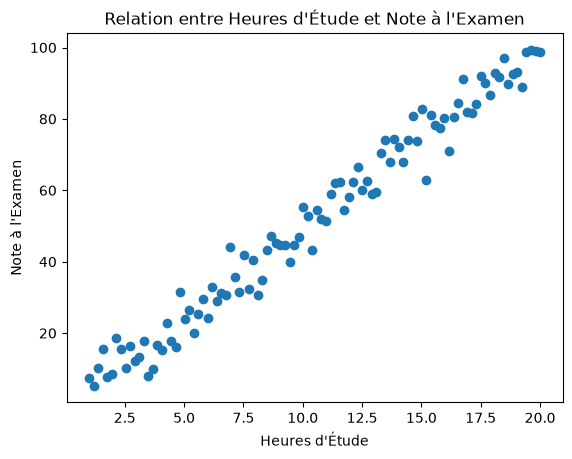

In [3]:
#afficher les données sous forme d'un nuage de données 
plt.scatter(data1['Heures_Etude'],data1['Note_Examen'])
plt.title("Relation entre Heures d'Étude et Note à l'Examen")

# Ajouter noms des axes
plt.xlabel("Heures d'Étude")
plt.ylabel("Note à l'Examen")


In [4]:
#séparer les variables 
X = data1.iloc[:,:-1].values
Y = data1.iloc[:,-1].values

In [5]:
#diviser le dataset en ensemble d'entraînement et test 
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size = 0.25)

In [6]:
#construire le modèle de regression linéaire
regressor = LinearRegression()
regressor.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[5.03]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.3094
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[47.01]


In [7]:
#utiliser le modèle entrainé pour faire des prédictions
Y_pred = regressor.predict(X_test)
#predire une seule valeur
valeurPredite = regressor.predict([[1.5]])
valeurPredite

array([7.23469076])

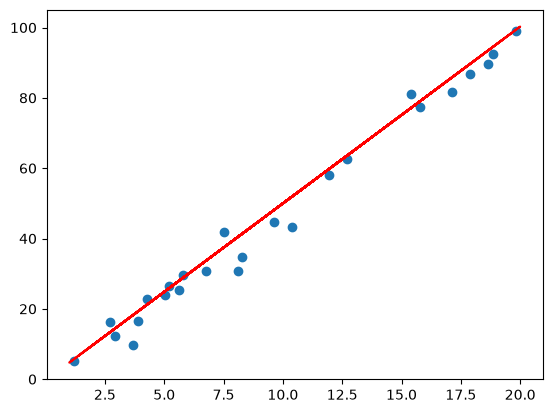

In [8]:
plt.scatter(X_test,Y_test)
plt.plot(X_train,regressor.predict(X_train), color = 'red')

In [9]:
# Afficher le coefficient (pente dans le cas simple, ou poids dans le cas multiple)
print("Coefficients :", regressor.coef_)

# Afficher l'ordonnée à l'origine (intercept)
print("Intercept :", regressor.intercept_)

Coefficients : [5.02938137]
Intercept : -0.30938130115935536


In [28]:
from sklearn.metrics import mean_squared_error, mean_absolute_error,root_mean_squared_error, r2_score
import numpy as np

MSE = mean_squared_error(Y_test, Y_pred)
MAE = mean_absolute_error(Y_test, Y_pred)
RMSE =root_mean_squared_error(Y_test, Y_pred)
R2 = r2_score(Y_test, Y_pred)

print("MSE:", MSE)
print("MAE:", MAE)
print("RMSE:", RMSE)
print("R2:", R2)

MSE: 13.488106800577219
MAE: 2.747688900405181
RMSE: 3.672615798116816
R2: 0.9320881821224812


In [10]:
#Deuxième cas d'étude est une regression multiple entre trois variables : Surface + nombre de chambres vs Prix maison
#l'importation du dataset
data2 = pd.read_csv("multiple_regression_real.csv")
#affichage des données importées
data2

,Surface_m2,Chambres,Prix_Maison
0,186,1,182920.857003
1,111,4,131094.004504
2,100,3,121424.511143
3,108,3,146400.053766
4,167,5,234812.910770
...,...,...,...
95,177,3,203165.124738
96,185,4,233862.019661
97,184,5,231662.968207
98,194,2,214443.505575


In [11]:
#Séparer les variables explicatives et la variable cible
X = data2.iloc[:,:-1]
Y = data2.iloc[:,-1]

In [12]:
#Séparer les données en entraînement et test 
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size = 0.25)

In [13]:
#entraînement du modèle
Regressor1 = LinearRegression()
Regressor1.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[ 968.89,11596.76]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['Surface_m2','Chambres']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,548.4
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [14]:
#utiliser le modèle entrainé pour faire des prédictions
Y_pred = Regressor1.predict(X_test)
#predire une seule valeur
valeurPredite = Regressor1.predict([[100,3]])
valeurPredite

c:\Users\ALI\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([132227.75263157])

c:\Users\ALI\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


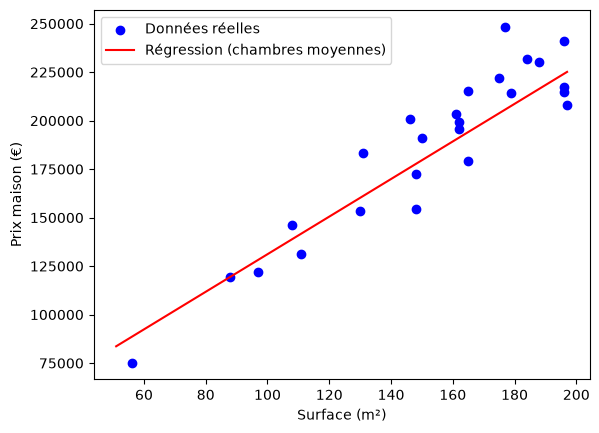

In [15]:
#On fixe une variable à la moyenne (ou à une valeur constante) pour :

# 1. Réduire la dimension et obtenir une visualisation 2D lisible.

# 2. Observer l’effet isolé d’une variable sur la cible.

# 3. Rendre la représentation interprétable.

# On récupère la colonne "Surface_m2"
surface_range = np.linspace(X_train["Surface_m2"].min(), 
                            X_train["Surface_m2"].max(), 100).reshape(-1,1)

# On fixe "Chambres" à sa moyenne
chambres_mean = np.full((100,1), X_train["Chambres"].mean())

# On construit un nouveau jeu de données pour la prédiction
X_plot = np.hstack((surface_range, chambres_mean))

# Tracé : nuage de points (surface vs prix)
plt.scatter(X_test["Surface_m2"], Y_test, color="blue", label="Données réelles")

# Tracé : droite de régression
plt.plot(surface_range, Regressor1.predict(X_plot), color="red", label="Régression (chambres moyennes)")

plt.xlabel("Surface (m²)")
plt.ylabel("Prix maison (€)")
plt.legend()
plt.show()


In [16]:
print("Coefficients :", Regressor1.coef_)
print("Intercept :", Regressor1.intercept_)

Coefficients : [  968.89042029 11596.75764075]
Intercept : 548.4376802087645


In [17]:
#Troisième cas d'étude est une regression polinomiale entre deux variables : la vitesse d’une voiture en fonction du temps écoulé depuis son démarrage
#l'importation du dataset
data3 = pd.read_csv("polynomial_regression_real.csv")
#affichage des données importées
data3

,Temps_s,Vitesse_kmh
0,0.000000,35.136521
1,0.141414,31.208833
2,0.282828,38.225857
3,0.424242,38.524643
4,0.565657,35.554574
...,...,...
95,13.434343,61.523047
96,13.575758,64.960477
97,13.717172,62.673138
98,13.858586,54.935832


In [18]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score

#Séparer le variable explicative et la variable cible
X = data3.iloc[:,:-1]
Y = data3.iloc[:,-1]

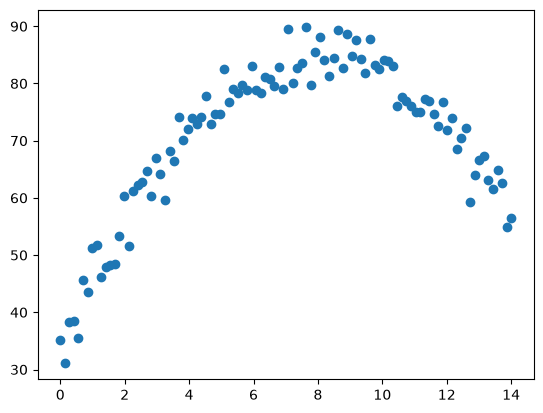

In [19]:
#représenter le dataset sous forme d'un nuage de points
plt.scatter(X,Y)

In [20]:
regressor3 = LinearRegression()
regressor3.fit(X,Y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[1.7]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Temps_s']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,58.8
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


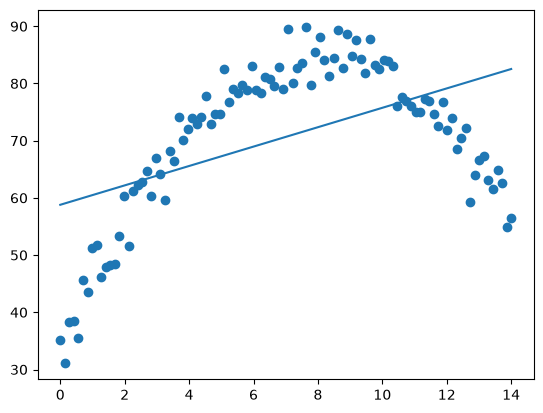

In [21]:
#Visualiser les résultats 
plt.scatter(X,Y)
plt.plot(X,regressor3.predict(X))
Y_pred = regressor3.predict(X)
#on peut constater que la régression linéaire n'est pas le chois parfait pour la modélisation

In [22]:
r2 = r2_score(Y,Y_pred)
r2

0.24929698157100777

In [23]:
#passer à une regression polinomiale 
poly_regression = PolynomialFeatures(degree = 3)
X_polynomial = poly_regression.fit_transform(X)
regressor4 = LinearRegression()
regressor4.fit(X_polynomial,Y)
Y_polynomial = regressor4.predict(X_polynomial)

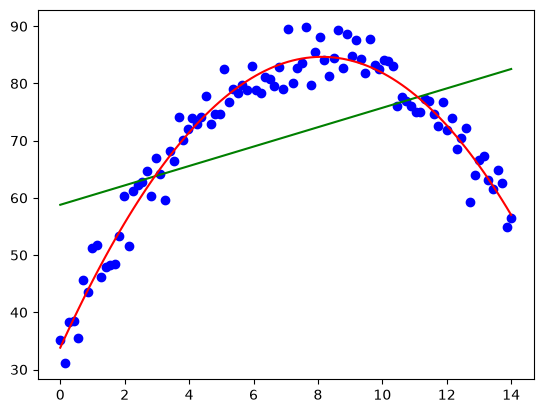

In [24]:
#affichage des résultats
plt.scatter(X,Y,color='blue')
plt.plot(X,regressor3.predict(X),color='green')
plt.plot(X,regressor4.predict(X_polynomial),color='red')

In [25]:
r2_pol = r2_score(Y,Y_polynomial)
r2_pol

0.9537357017811652

In [26]:
#Travail à réaliser :
###Tester la regression polynomiale pour 5 différentes valeurs de degree polynomiale
###Dessiner un tableau qui compare la performance du modèle pour les 5 degrees en utilisant le métrique r2_score
###essayer de tester la performance par d'autres métriques vus dans le cours 
###Conclure au meilleure degree

### Regression polynomiale pour 5 différentes valeurs de degree polynomiale

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

X = data3.iloc[:,:-1].values
Y = data3.iloc[:,-1].values

X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.25)

predictions = {}

degrees = [1, 2, 3, 4, 5]

for deg in degrees:
    poly_reg = PolynomialFeatures(degree=deg)
    X_train_poly = poly_reg.fit_transform(X_train)
    X_test_poly = poly_reg.transform(X_test)
    
    regressor = LinearRegression()
    regressor.fit(X_train_poly, Y_train)
    
    predictions[deg] = regressor.predict(X_test_poly)


### Tableau qui compare la performance du modèle pour les 5 degrees en utilisant le métrique r2_score

In [34]:
from sklearn.metrics import r2_score
r2_scores = []
for deg in degrees:
    r2_scores.append(r2_score(Y_test, predictions[deg]))

tableau = pd.DataFrame({'Degré': degrees, 'R2 Score': r2_scores})
tableau

,Degré,R2 Score
0,1,0.309579
1,2,0.943903
2,3,0.943237
3,4,0.943277
4,5,0.914600


### Test avec les autres metrique du cours  

In [35]:
from sklearn.metrics import mean_squared_error, mean_absolute_error , root_mean_squared_error
mse_scores = []
mae_scores = []
rmse_scores = []

for deg in degrees:
    mse_scores.append(mean_squared_error(Y_test, predictions[deg]))
    mae_scores.append(mean_absolute_error(Y_test, predictions[deg]))
    rmse_scores.append(root_mean_squared_error(Y_test, predictions[deg]))

tableau = pd.DataFrame({
    'Degré': degrees,
    'R2 Score': r2_scores,
    'MSE': mse_scores,
    'MAE': mae_scores,
    'RMSE': rmse_scores
})
tableau


,Degré,R2 Score,MSE,MAE,RMSE
0,1,0.309579,140.182520,9.451748,11.839870
1,2,0.943903,11.389820,2.927251,3.374881
2,3,0.943237,11.525209,2.909853,3.394880
3,4,0.943277,11.516992,2.910730,3.393669
4,5,0.914600,17.339578,3.538454,4.164082


### Conclusion
- Le degré 1 (régression linéaire) donne un R² faible : le modèle est trop simple (sous-apprentissage).
- Le meilleur degré est 2 car il a le R² le plus proche de 1 et les erreurs (MAE, MSE, RMSE) les plus faibles.
- Au-delà de ce degré, les performances n'augmentent presque plus : un degré trop élevé complique le modèle
  inutilement et risque le surapprentissage (overfitting).
  